# PHÂN TÍCH BMI VÀ HUYẾT ÁP TÂM THU

**Đề tài:** Chất lượng dữ liệu và mối liên quan giữa chỉ số khối cơ thể với huyết áp tâm thu trong khám sức khỏe định kỳ cộng đồng: nghiên cứu cắt ngang ở người 18–59 tuổi năm 2026.

- **Đơn vị phân tích:** một lượt khám sức khỏe hợp lệ.
- **Dữ liệu:** `Research_Data.csv` đã khử định danh, *n = 7.146*.
- **Nguyên tắc diễn giải:** phân tích mối liên quan trong mẫu; không suy luận nguyên nhân–kết quả, không chẩn đoán cá nhân và không suy rộng đại diện toàn quốc.


In [1]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['font.family'] = ['Arial Unicode MS', 'DejaVu Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path('/Users/springwang/Library/Mobile Documents/com~apple~CloudDocs/FinalYear/DA')
DATA_PATH = ROOT / 'outputs/m3_research_dataset_20261027/Research_Data.csv'
OUT_DIR = ROOT / 'outputs/M3_BMI_HuyetAp_Final_Project'
FIG_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('scipy:', stats.__version__ if hasattr(stats, '__version__') else 'available')
print('Dữ liệu:', DATA_PATH)

Python: 3.13.13
pandas: 3.0.3
numpy: 2.5.0
scipy: available
Dữ liệu: /Users/springwang/Library/Mobile Documents/com~apple~CloudDocs/FinalYear/DA/outputs/m3_research_dataset_20261027/Research_Data.csv


## 1. Câu hỏi, giả thuyết và kế hoạch kiểm định

**Câu hỏi chính:** Trong mẫu khám sức khỏe đã làm sạch, BMI có còn liên quan với huyết áp tâm thu sau khi xét tuổi, giới tính và mạch không?

**Câu hỏi phụ theo rubric:**

1. Huyết áp tâm thu có khác theo giới tính không? — Welch t-test.
2. Huyết áp tâm thu có khác theo nhóm BMI/nhóm tuổi không? — ANOVA một yếu tố.
3. Cờ sàng lọc huyết áp ≥140/90 có liên quan với nhóm BMI không? — Chi-square.
4. BMI có tương quan với huyết áp tâm thu không? — Pearson và Spearman.
5. Hồi quy đa biến: `HATT ~ BMI + tuổi + giới tính + mạch`.

Mức ý nghĩa quy ước: α = 0,05; luôn báo cáo kích thước hiệu ứng, không chỉ p-value.


In [2]:
df = pd.read_csv(DATA_PATH)
assert df.shape == (7146, 14), f'Kích thước không như kỳ vọng: {df.shape}'
assert df['Mã nghiên cứu'].is_unique

# Tên biến nội bộ ngắn, giữ nguyên giá trị nguồn.
rename = {
    'Tuổi (năm)': 'age', 'Giới tính': 'sex', 'Chiều cao (cm)': 'height_cm',
    'Cân nặng (kg)': 'weight_kg', 'BMI (kg/m²)': 'bmi',
    'Nhóm BMI phân tích': 'bmi_group', 'Mạch (lần/phút)': 'pulse',
    'Huyết áp tâm thu (mmHg)': 'sbp', 'Huyết áp tâm trương (mmHg)': 'dbp',
    'Cờ sàng lọc HA ≥140/90': 'bp_screen', 'Cờ mã nguồn lặp': 'repeat_flag',
    'Nhóm tuổi': 'age_group', 'Tháng khám': 'exam_month', 'Mã nghiên cứu': 'research_id'
}
df = df.rename(columns=rename)
num_cols = ['age', 'height_cm', 'weight_kg', 'bmi', 'pulse', 'sbp', 'dbp']
print('Kích thước:', df.shape)
pd.DataFrame({'Kiểu dữ liệu': df.dtypes.astype(str), 'Số thiếu': df.isna().sum()})

Kích thước: (7146, 14)


,Kiểu dữ liệu,Số thiếu
research_id,str,0
exam_month,str,0
age,int64,0
age_group,str,0
sex,str,0
height_cm,float64,0
weight_kg,float64,0
bmi,float64,0
bmi_group,str,0
pulse,int64,0


## 2. Kiểm tra chất lượng dữ liệu

Các ngưỡng hợp lý đã được áp dụng khi tạo bộ dữ liệu nghiên cứu. Phần này không chẩn đoán bất thường y khoa; nó kiểm tra tính đầy đủ, duy nhất và giá trị cực trị theo thống kê để minh bạch cho người đọc.


In [3]:
quality = pd.DataFrame({
    'Số bản ghi': [len(df)],
    'Số biến': [df.shape[1]],
    'Thiếu dữ liệu': [int(df.isna().sum().sum())],
    'Mã nghiên cứu trùng': [int(df['research_id'].duplicated().sum())],
    'Cờ mã nguồn lặp': [int(df['repeat_flag'].sum())],
})
quality

missing = df.isna().sum().rename('Số thiếu').to_frame()
missing['Tỷ lệ thiếu (%)'] = (missing['Số thiếu'] / len(df) * 100).round(2)
missing

,Số thiếu,Tỷ lệ thiếu (%)
research_id,0,0.0
exam_month,0,0.0
age,0,0.0
age_group,0,0.0
sex,0,0.0
height_cm,0,0.0
weight_kg,0,0.0
bmi,0,0.0
bmi_group,0,0.0
pulse,0,0.0


In [4]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Ngưỡng dưới': lo, 'Ngưỡng trên': hi,
                      'Số cờ IQR': int(((s < lo) | (s > hi)).sum())})

outlier_audit = df[num_cols].apply(iqr_flags).T.round(2)
outlier_audit

# Các điểm cực trị thống kê được giữ lại trong phân tích chính; độ nhạy kiểm tra ở phần cuối.
summary = df[num_cols].describe(percentiles=[.25, .5, .75]).T
summary['median'] = df[num_cols].median()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median
age,7146.0,36.46,12.70,18.00,25.00,35.00,48.00,59.00,35.00
height_cm,7146.0,161.38,8.67,106.00,155.00,160.00,168.00,199.00,160.00
weight_kg,7146.0,62.26,13.24,27.00,53.00,60.00,70.00,145.00,60.00
bmi,7146.0,23.79,4.00,13.52,21.09,23.34,25.89,57.02,23.34
pulse,7146.0,81.10,10.44,42.00,75.00,80.00,87.00,182.00,80.00
sbp,7146.0,120.07,16.31,80.00,110.00,120.00,130.00,220.00,120.00
dbp,7146.0,77.44,10.72,43.00,70.00,78.00,82.00,150.00,78.00


## 3. Phân tích khám phá dữ liệu (EDA)

Các biểu đồ sau lần lượt cho thấy hình dạng phân phối, sự khác biệt giữa các nhóm và quan hệ liên tục BMI–huyết áp tâm thu.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


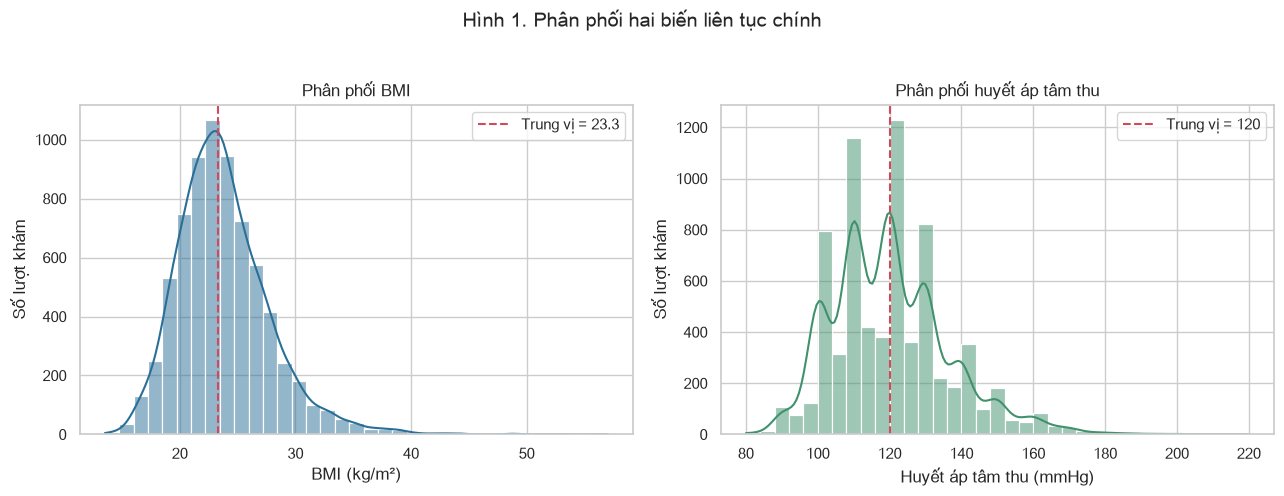

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(df['bmi'], bins=35, kde=True, color='#2A6F97', ax=axes[0])
axes[0].axvline(df['bmi'].median(), color='#D1495B', ls='--', label=f'Trung vị = {df.bmi.median():.1f}')
axes[0].set(title='Phân phối BMI', xlabel='BMI (kg/m²)', ylabel='Số lượt khám')
axes[0].legend()
sns.histplot(df['sbp'], bins=35, kde=True, color='#40916C', ax=axes[1])
axes[1].axvline(df['sbp'].median(), color='#D1495B', ls='--', label=f'Trung vị = {df.sbp.median():.0f}')
axes[1].set(title='Phân phối huyết áp tâm thu', xlabel='Huyết áp tâm thu (mmHg)', ylabel='Số lượt khám')
axes[1].legend()
fig.suptitle('Hình 1. Phân phối hai biến liên tục chính', y=1.03, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR/'01_distributions_bmi_sbp.png', dpi=180, bbox_inches='tight')
plt.show()

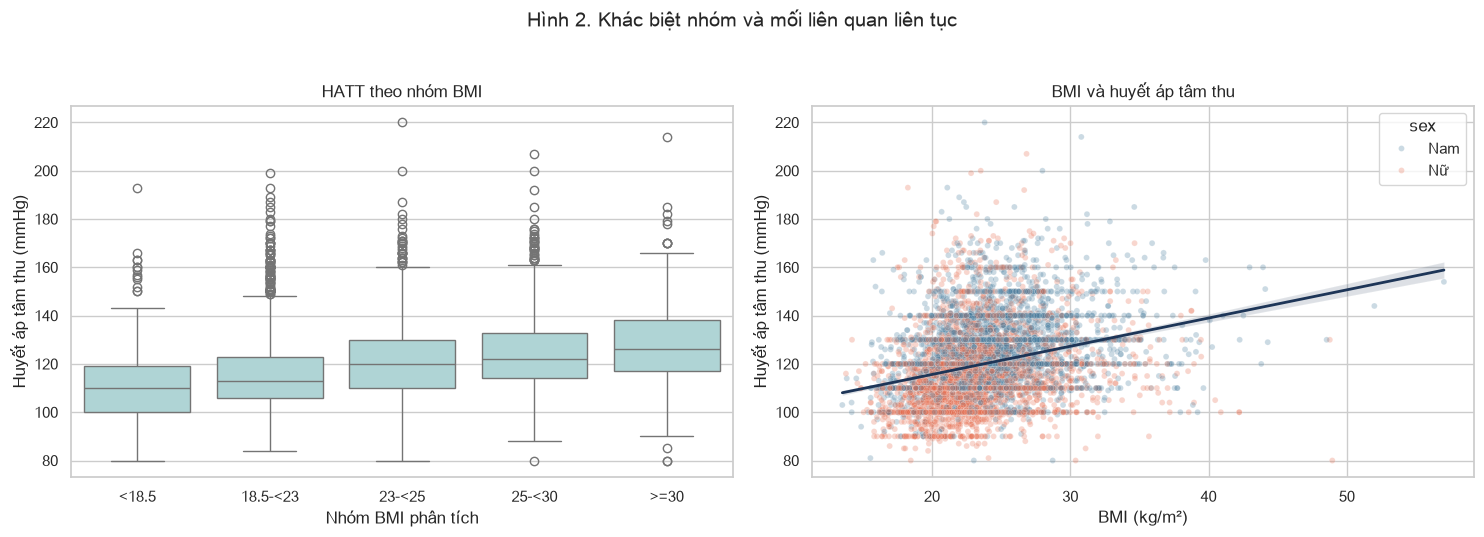

In [6]:
order_bmi = ['<18.5', '18.5-<23', '23-<25', '25-<30', '>=30']
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.boxplot(data=df, x='bmi_group', y='sbp', order=order_bmi, color='#A8DADC', ax=axes[0])
axes[0].set(title='HATT theo nhóm BMI', xlabel='Nhóm BMI phân tích', ylabel='Huyết áp tâm thu (mmHg)')
sns.scatterplot(data=df, x='bmi', y='sbp', hue='sex', alpha=.28, s=18, ax=axes[1], palette=['#457B9D', '#E76F51'])
sns.regplot(data=df, x='bmi', y='sbp', scatter=False, color='#1D3557', ax=axes[1], line_kws={'lw':2})
axes[1].set(title='BMI và huyết áp tâm thu', xlabel='BMI (kg/m²)', ylabel='Huyết áp tâm thu (mmHg)')
fig.suptitle('Hình 2. Khác biệt nhóm và mối liên quan liên tục', y=1.03, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR/'02_bmi_groups_and_scatter.png', dpi=180, bbox_inches='tight')
plt.show()

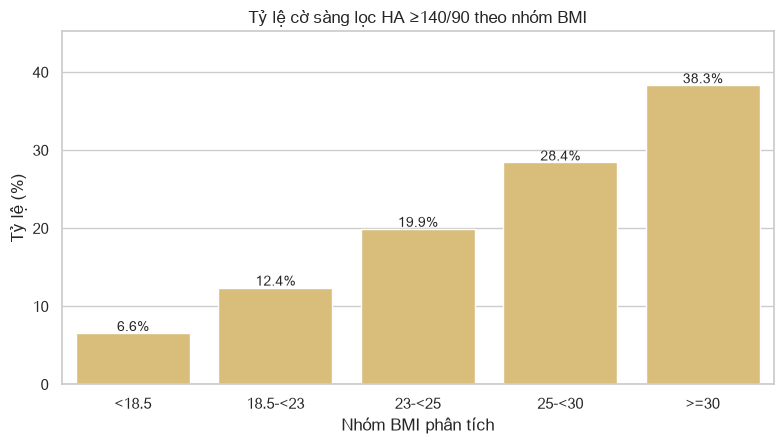

,Số lượt khám,Số cờ sàng lọc,mean,Tỷ lệ sàng lọc (%)
bmi_group,,,,
<18.5,425,28,0.07,6.59
18.5-<23,2861,355,0.12,12.41
23-<25,1555,310,0.20,19.94
25-<30,1825,519,0.28,28.44
>=30,480,184,0.38,38.33


In [7]:
screen_table = (df.groupby('bmi_group', observed=False)['bp_screen']
                  .agg(['count', 'sum', 'mean']).reindex(order_bmi))
screen_table['Tỷ lệ sàng lọc (%)'] = 100 * screen_table['mean']
screen_table = screen_table.rename(columns={'count':'Số lượt khám', 'sum':'Số cờ sàng lọc'})

fig, ax = plt.subplots(figsize=(8, 4.6))
sns.barplot(data=screen_table.reset_index(), x='bmi_group', y='Tỷ lệ sàng lọc (%)', color='#E9C46A', ax=ax)
ax.set(title='Tỷ lệ cờ sàng lọc HA ≥140/90 theo nhóm BMI', xlabel='Nhóm BMI phân tích', ylabel='Tỷ lệ (%)')
ax.set_ylim(0, max(screen_table['Tỷ lệ sàng lọc (%)']) * 1.18)
for i, value in enumerate(screen_table['Tỷ lệ sàng lọc (%)']):
    ax.text(i, value + .25, f'{value:.1f}%', ha='center', fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR/'03_screening_rate_by_bmi.png', dpi=180, bbox_inches='tight')
plt.show()
screen_table.round(2)

## 4. Kiểm định giả thuyết

Kiểm định hai phía; kết quả có ý nghĩa thống kê được đặt cạnh kích thước hiệu ứng để tránh nhầm lẫn giữa ý nghĩa thống kê và ý nghĩa thực tiễn.


In [8]:
# Welch t-test: HATT giữa hai giới; Cohen's d với độ lệch chuẩn gộp.
groups = [x['sbp'].to_numpy() for _, x in df.groupby('sex', observed=False)]
sex_names = list(df.groupby('sex', observed=False).groups.keys())
t_stat, p_t = stats.ttest_ind(*groups, equal_var=False)
n1, n2 = map(len, groups)
s1, s2 = map(np.std, groups)
pooled_sd = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
cohen_d = (groups[0].mean() - groups[1].mean()) / pooled_sd
ttest_results = pd.DataFrame({
    'Nhóm': sex_names, 'n': [n1, n2], 'HATT trung bình': [groups[0].mean(), groups[1].mean()],
    'Độ lệch chuẩn': [s1, s2]
}).round(2)
print('Welch t-test: t = %.3f, p = %.6g, Cohen d = %.3f' % (t_stat, p_t, cohen_d))
ttest_results

Welch t-test: t = 26.581, p = 1.62369e-148, Cohen d = 0.629


,Nhóm,n,HATT trung bình,Độ lệch chuẩn
0,Nam,3426,125.16,15.32
1,Nữ,3720,115.37,15.78


In [9]:
# ANOVA: HATT theo nhóm BMI và theo nhóm tuổi; eta squared.
def anova_with_eta(data, group_col, outcome):
    prepared = [g[outcome].to_numpy() for _, g in data.groupby(group_col, observed=False)]
    f, p = stats.f_oneway(*prepared)
    grand = data[outcome].mean()
    ss_between = sum(len(g) * (g[outcome].mean() - grand)**2 for _, g in data.groupby(group_col, observed=False))
    ss_total = ((data[outcome] - grand)**2).sum()
    eta_sq = ss_between / ss_total
    table = data.groupby(group_col, observed=False)[outcome].agg(['count','mean','std']).round(2)
    return f, p, eta_sq, table

for grouping, label in [('bmi_group', 'nhóm BMI'), ('age_group', 'nhóm tuổi')]:
    f, p, eta, table = anova_with_eta(df, grouping, 'sbp')
    print(f'ANOVA HATT theo {label}: F = {f:.3f}, p = {p:.6g}, eta² = {eta:.3f}')
    display(table)

ANOVA HATT theo nhóm BMI: F = 162.401, p = 2.93103e-133, eta² = 0.083


,count,mean,std
bmi_group,,,
18.5-<23,2861,116.16,15.37
23-<25,1555,121.68,15.80
25-<30,1825,125.04,15.70
<18.5,425,110.56,14.42
>=30,480,127.60,17.16


ANOVA HATT theo nhóm tuổi: F = 186.611, p = 1.67365e-116, eta² = 0.073


,count,mean,std
age_group,,,
18-29,2688,116.34,13.55
30-39,1488,117.48,14.76
40-49,1442,121.66,16.74
50-59,1528,127.63,18.83


In [10]:
# Chi-square: nhóm BMI và cờ sàng lọc HA ≥140/90; Cramer's V.
ct = pd.crosstab(df['bmi_group'], df['bp_screen']).reindex(order_bmi)
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
n = ct.to_numpy().sum()
phi2 = chi2 / n
r, k = ct.shape
cramers_v = np.sqrt(phi2 / min(k-1, r-1))
print(f'Chi-square: χ²({dof}) = {chi2:.3f}, p = {p_chi:.6g}, Cramér V = {cramers_v:.3f}')
ct.assign(**{'Tỷ lệ sàng lọc (%)': (ct[1] / ct.sum(axis=1) * 100).round(2)})

Chi-square: χ²(4) = 337.862, p = 7.31988e-72, Cramér V = 0.217


bp_screen,0,1,Tỷ lệ sàng lọc (%)
bmi_group,,,
<18.5,397,28,6.59
18.5-<23,2506,355,12.41
23-<25,1245,310,19.94
25-<30,1306,519,28.44
>=30,296,184,38.33


In [11]:
# Tương quan BMI–HATT: Pearson (tuyến tính) và Spearman (đơn điệu, bền vững hơn với lệch phân phối).
pearson_r, pearson_p = stats.pearsonr(df['bmi'], df['sbp'])
spearman_rho, spearman_p = stats.spearmanr(df['bmi'], df['sbp'])
corr_results = pd.DataFrame({
    'Phương pháp': ['Pearson', 'Spearman'],
    'Hệ số': [pearson_r, spearman_rho],
    'p-value': [pearson_p, spearman_p]
})
corr_results.round(4)

,Phương pháp,Hệ số,p-value
0,Pearson,0.2867,0.0
1,Spearman,0.3351,0.0


## 5. Hồi quy tuyến tính đa biến

Mô hình chính dùng HATT là biến kết quả liên tục. Giới tính được mã hóa `Nam = 1`, `Nữ = 0` (nhóm tham chiếu). Không đưa HATTr vào mô hình vì đó là phép đo huyết áp đồng thời, không phải biến nền thích hợp để điều chỉnh trong câu hỏi này.


In [12]:
# OLS bằng đại số tuyến tính; SE, t-test và CI 95% được tính từ ma trận hiệp phương sai.
y = df['sbp'].to_numpy(dtype=float)
sex_male = (df['sex'] == 'Nam').astype(int).to_numpy()
X = np.column_stack([np.ones(len(df)), df['bmi'], df['age'], sex_male, df['pulse']])
term_names = ['Hằng số', 'BMI (kg/m²)', 'Tuổi (năm)', 'Nam so với Nữ', 'Mạch (lần/phút)']

beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
fitted = X @ beta
resid = y - fitted
n, p = X.shape
rss = (resid**2).sum()
tss = ((y-y.mean())**2).sum()
r2 = 1-rss/tss
adj_r2 = 1-(1-r2)*(n-1)/(n-p)
sigma2 = rss/(n-p)
cov_beta = sigma2 * np.linalg.inv(X.T @ X)
se = np.sqrt(np.diag(cov_beta))
t_values = beta/se
p_values = 2 * stats.t.sf(np.abs(t_values), df=n-p)
t_crit = stats.t.ppf(.975, df=n-p)
regression = pd.DataFrame({
    'Biến': term_names, 'Hệ số β': beta, 'SE': se, 't': t_values, 'p-value': p_values,
    'CI 95% thấp': beta-t_crit*se, 'CI 95% cao': beta+t_crit*se
})
print(f'n = {n:,}; R² = {r2:.3f}; R² hiệu chỉnh = {adj_r2:.3f}; RMSE = {np.sqrt(sigma2):.2f} mmHg')
regression.round(4)

n = 7,146; R² = 0.257; R² hiệu chỉnh = 0.256; RMSE = 14.07 mmHg


,Biến,Hệ số β,SE,t,p-value,CI 95% thấp,CI 95% cao
0,Hằng số,59.7952,1.6961,35.2552,0.0,56.4704,63.1200
1,BMI (kg/m²),0.8608,0.0425,20.2751,0.0,0.7776,0.9440
2,Tuổi (năm),0.4047,0.0133,30.3256,0.0,0.3785,0.4308
3,Nam so với Nữ,9.9668,0.3426,29.0908,0.0,9.2952,10.6384
4,Mạch (lần/phút),0.2498,0.0161,15.5203,0.0,0.2182,0.2813


In [13]:
# VIF và chẩn đoán phần dư. VIF cao cho thấy đa cộng tuyến giữa các biến giải thích.
def vif_for_column(matrix, j):
    target = matrix[:, j]
    others = np.delete(matrix, j, axis=1)
    others = np.column_stack([np.ones(len(others)), others])
    pred = others @ np.linalg.lstsq(others, target, rcond=None)[0]
    r2_j = 1 - ((target-pred)**2).sum() / ((target-target.mean())**2).sum()
    return 1/(1-r2_j)

features = np.column_stack([df['bmi'], df['age'], sex_male, df['pulse']])
vif = pd.DataFrame({'Biến': term_names[1:], 'VIF': [vif_for_column(features, j) for j in range(features.shape[1])]})
dw = np.sum(np.diff(resid)**2) / np.sum(resid**2)
print('Durbin–Watson (mô tả): %.3f' % dw)
vif.round(3)

Durbin–Watson (mô tả): 2.004


,Biến,VIF
0,BMI (kg/m²),1.043
1,Tuổi (năm),1.038
2,Nam so với Nữ,1.058
3,Mạch (lần/phút),1.018


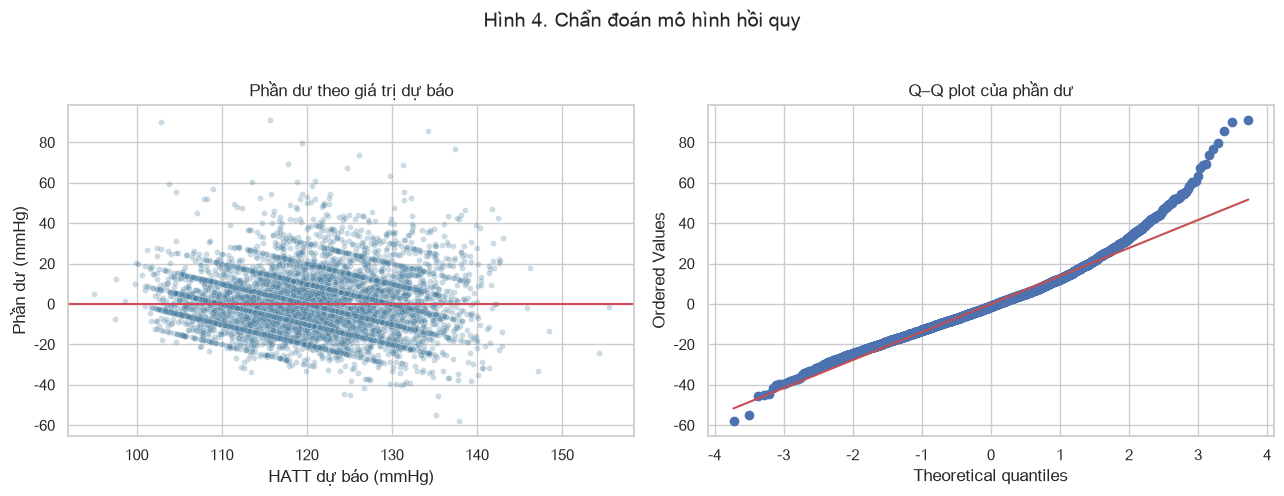

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(x=fitted, y=resid, alpha=.28, s=18, color='#457B9D', ax=axes[0])
axes[0].axhline(0, color='#D1495B', lw=1.5)
axes[0].set(title='Phần dư theo giá trị dự báo', xlabel='HATT dự báo (mmHg)', ylabel='Phần dư (mmHg)')
stats.probplot(resid, dist='norm', plot=axes[1])
axes[1].set_title('Q–Q plot của phần dư')
fig.suptitle('Hình 4. Chẩn đoán mô hình hồi quy', y=1.03, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR/'04_regression_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Phân tích độ nhạy và kết luận

Do cờ mã nguồn lặp đã được giữ lại để minh bạch, kiểm tra dưới đây so sánh hệ số BMI trong mô hình chính với mô hình bỏ các dòng mang cờ này. Nếu thay đổi nhỏ, kết quả chính bền vững hơn trước quyết định xử lý bản ghi lặp.


In [15]:
def bmi_coefficient(data):
    yy = data['sbp'].to_numpy(float)
    male = (data['sex'] == 'Nam').astype(int).to_numpy()
    xx = np.column_stack([np.ones(len(data)), data['bmi'], data['age'], male, data['pulse']])
    bb, _, _, _ = np.linalg.lstsq(xx, yy, rcond=None)
    return bb[1]

sensitivity = pd.DataFrame({
    'Mẫu': ['Phân tích chính', 'Bỏ dòng cờ mã nguồn lặp'],
    'n': [len(df), int((df['repeat_flag']==0).sum())],
    'Hệ số BMI (mmHg / 1 BMI)': [bmi_coefficient(df), bmi_coefficient(df[df['repeat_flag']==0])]
}).round(4)
sensitivity

,Mẫu,n,Hệ số BMI (mmHg / 1 BMI)
0,Phân tích chính,7146,0.8608
1,Bỏ dòng cờ mã nguồn lặp,7028,0.8522


In [16]:
# Xuất bảng kết quả: dùng trực tiếp cho báo cáo/slide, tách khỏi dữ liệu vi mô.
RESULT_DIR = OUT_DIR / 'tables'
RESULT_DIR.mkdir(exist_ok=True)
summary.round(3).to_csv(RESULT_DIR/'01_descriptive_statistics.csv', encoding='utf-8-sig')
missing.to_csv(RESULT_DIR/'02_missingness.csv', encoding='utf-8-sig')
outlier_audit.to_csv(RESULT_DIR/'03_iqr_outlier_audit.csv', encoding='utf-8-sig')
screen_table.round(3).to_csv(RESULT_DIR/'04_screening_by_bmi.csv', encoding='utf-8-sig')
corr_results.round(6).to_csv(RESULT_DIR/'05_bmi_sbp_correlation.csv', index=False, encoding='utf-8-sig')
regression.round(6).to_csv(RESULT_DIR/'06_adjusted_ols_regression.csv', index=False, encoding='utf-8-sig')
sensitivity.to_csv(RESULT_DIR/'07_sensitivity_repeat_flag.csv', index=False, encoding='utf-8-sig')
stat_summary = pd.DataFrame([
    ['Welch t-test: HATT theo giới', t_stat, p_t, 'Cohen d', cohen_d],
    ['ANOVA: HATT theo nhóm BMI', anova_with_eta(df, 'bmi_group', 'sbp')[0], anova_with_eta(df, 'bmi_group', 'sbp')[1], 'eta²', anova_with_eta(df, 'bmi_group', 'sbp')[2]],
    ['ANOVA: HATT theo nhóm tuổi', anova_with_eta(df, 'age_group', 'sbp')[0], anova_with_eta(df, 'age_group', 'sbp')[1], 'eta²', anova_with_eta(df, 'age_group', 'sbp')[2]],
    ['Chi-square: nhóm BMI × cờ sàng lọc', chi2, p_chi, 'Cramér V', cramers_v],
    ['Pearson: BMI–HATT', pearson_r, pearson_p, 'r', pearson_r],
    ['Spearman: BMI–HATT', spearman_rho, spearman_p, 'rho', spearman_rho],
], columns=['Phân tích','Thống kê','p-value','Kích thước hiệu ứng','Giá trị hiệu ứng'])
stat_summary.to_csv(RESULT_DIR/'08_hypothesis_tests_summary.csv', index=False, encoding='utf-8-sig')
print(f'Đã xuất {len(list(RESULT_DIR.glob("*.csv")))} bảng kết quả vào: {RESULT_DIR}')
stat_summary.round(4)

Đã xuất 8 bảng kết quả vào: /Users/springwang/Library/Mobile Documents/com~apple~CloudDocs/FinalYear/DA/outputs/M3_BMI_HuyetAp_Final_Project/tables


,Phân tích,Thống kê,p-value,Kích thước hiệu ứng,Giá trị hiệu ứng
0,Welch t-test: HATT theo giới,26.5811,0.0,Cohen d,0.6287
1,ANOVA: HATT theo nhóm BMI,162.4012,0.0,eta²,0.0834
2,ANOVA: HATT theo nhóm tuổi,186.6108,0.0,eta²,0.0727
3,Chi-square: nhóm BMI × cờ sàng lọc,337.8618,0.0,Cramér V,0.2174
4,Pearson: BMI–HATT,0.2867,0.0,r,0.2867
5,Spearman: BMI–HATT,0.3351,0.0,rho,0.3351


## 6. Trực quan hóa mở rộng và insight phân tầng

Phần này bổ sung các hình dành cho báo cáo, slide và phụ lục. Mỗi hình trả lời một câu hỏi cụ thể: mẫu được hình thành thế nào, thành phần theo tuổi/giới ra sao, gradient huyết áp có ổn định theo tuổi–giới không, và nhóm nào có tỷ lệ cờ sàng lọc cao hơn.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


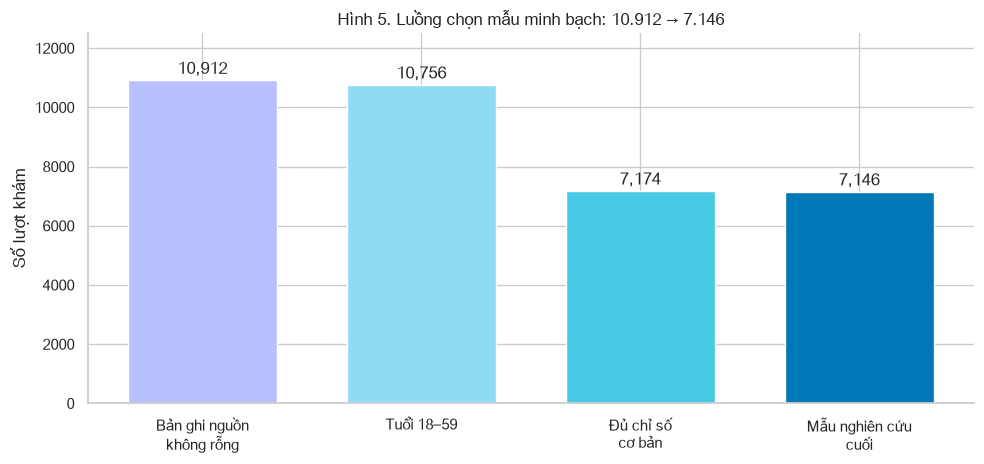

In [17]:
# Hình 5. Luồng hình thành mẫu từ audit đã công bố.
stages = pd.DataFrame({
    'Giai đoạn': ['Bản ghi nguồn\nkhông rỗng', 'Tuổi 18–59', 'Đủ chỉ số\ncơ bản', 'Mẫu nghiên cứu\ncuối'],
    'Số lượt': [10912, 10756, 7174, 7146]
})
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = ['#B8C0FF', '#90DBF4', '#48CAE4', '#0077B6']
bars = ax.bar(stages['Giai đoạn'], stages['Số lượt'], color=colors, edgecolor='white', width=.68)
ax.set_ylim(0, 12500)
ax.set_ylabel('Số lượt khám')
ax.set_title('Hình 5. Luồng chọn mẫu minh bạch: 10.912 → 7.146', fontweight='bold')
for bar, value in zip(bars, stages['Số lượt']):
    ax.text(bar.get_x()+bar.get_width()/2, value+220, f'{value:,}', ha='center', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'05_cohort_flow.png', dpi=180, bbox_inches='tight')
plt.show()

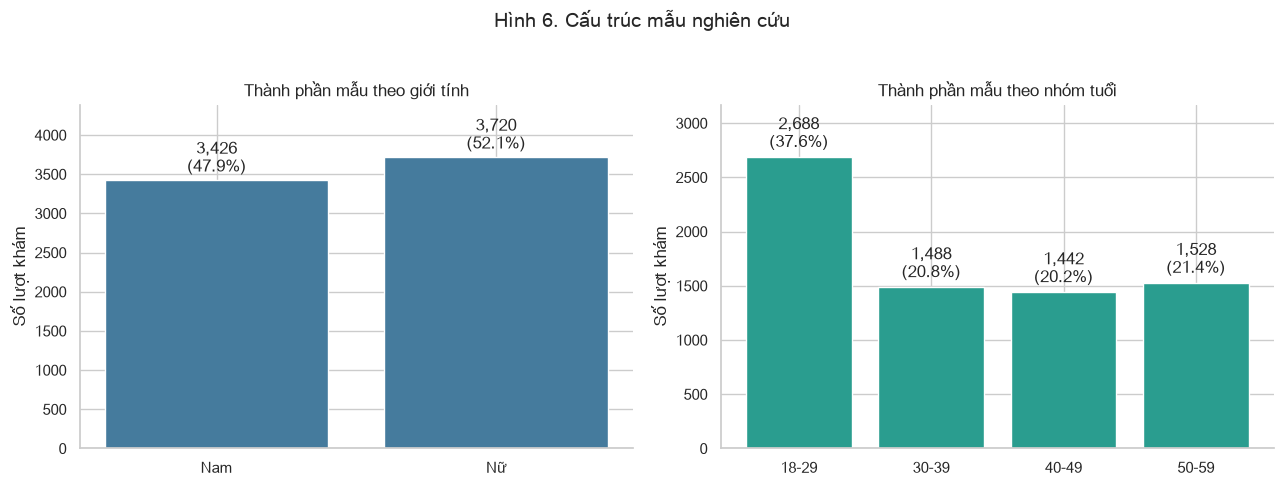

In [18]:
# Hình 6. Thành phần mẫu theo giới tính và nhóm tuổi.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
sex_counts = df['sex'].value_counts().reindex(['Nam','Nữ'])
age_counts = df['age_group'].value_counts().reindex(['18-29','30-39','40-49','50-59'])
for ax, series, title, color in [
    (axes[0], sex_counts, 'Thành phần mẫu theo giới tính', '#457B9D'),
    (axes[1], age_counts, 'Thành phần mẫu theo nhóm tuổi', '#2A9D8F')
]:
    bars = ax.bar(series.index, series.values, color=color)
    ax.set(title=title, ylabel='Số lượt khám')
    ax.set_ylim(0, max(series.values)*1.18)
    for bar, value in zip(bars, series.values):
        ax.text(bar.get_x()+bar.get_width()/2, value+50, f'{value:,}\n({value/len(df)*100:.1f}%)', ha='center', va='bottom')
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Hình 6. Cấu trúc mẫu nghiên cứu', y=1.03, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR/'06_sample_composition.png', dpi=180, bbox_inches='tight')
plt.show()

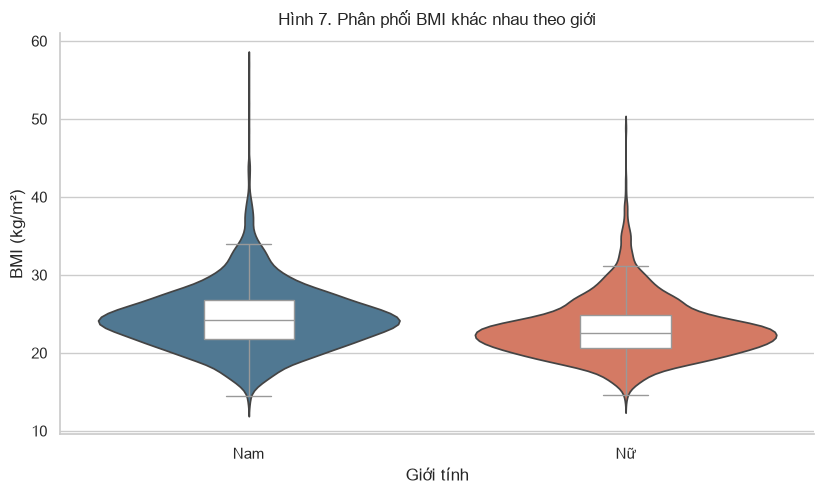

In [19]:
# Hình 7. Phân phối BMI theo giới: violin + boxplot để nhìn cả mật độ và trung vị.
fig, ax = plt.subplots(figsize=(8.4, 5.1))
sns.violinplot(data=df, x='sex', y='bmi', hue='sex', palette=['#457B9D','#E76F51'], inner=None, legend=False, ax=ax)
sns.boxplot(data=df, x='sex', y='bmi', width=.24, color='white', showfliers=False, ax=ax)
ax.set(title='Hình 7. Phân phối BMI khác nhau theo giới', xlabel='Giới tính', ylabel='BMI (kg/m²)')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'07_bmi_by_sex.png', dpi=180, bbox_inches='tight')
plt.show()

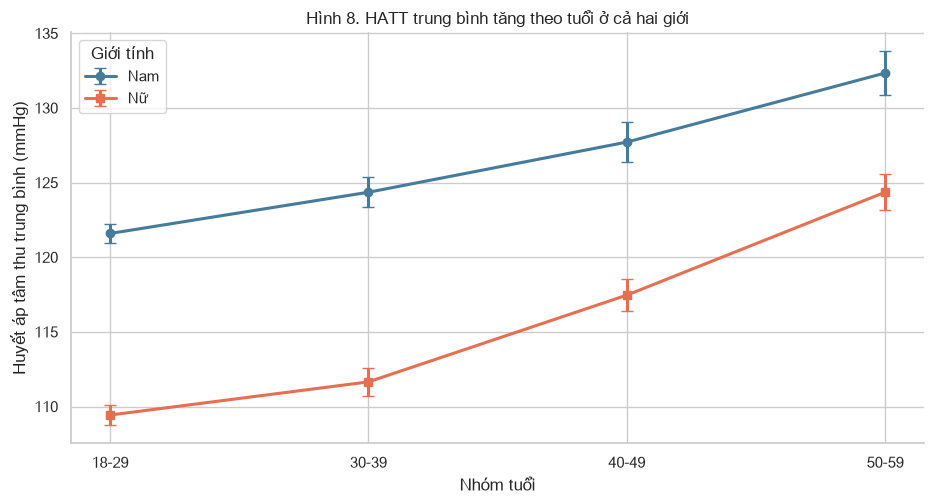

,age_group,sex,count,mean,std,se,ci_low,ci_high
0,18-29,Nam,1528,121.59,12.76,0.33,120.95,122.23
1,18-29,Nữ,1160,109.43,11.28,0.33,108.78,110.08
2,30-39,Nam,683,124.35,13.48,0.52,123.34,125.37
3,30-39,Nữ,805,111.65,13.22,0.47,110.74,112.56
4,40-49,Nam,590,127.71,16.29,0.67,126.40,129.03
5,40-49,Nữ,852,117.46,15.74,0.54,116.41,118.52
6,50-59,Nam,625,132.34,18.76,0.75,130.87,133.81
7,50-59,Nữ,903,124.36,18.19,0.61,123.17,125.55


In [20]:
# Hình 8. Gradient HATT theo tuổi và giới; điểm là trung bình, thanh là CI 95% bootstrap.
summary_age_sex = (df.groupby(['age_group','sex'], observed=False)['sbp']
                  .agg(['count','mean','std']).reset_index())
summary_age_sex['se'] = summary_age_sex['std'] / np.sqrt(summary_age_sex['count'])
summary_age_sex['ci_low'] = summary_age_sex['mean'] - 1.96*summary_age_sex['se']
summary_age_sex['ci_high'] = summary_age_sex['mean'] + 1.96*summary_age_sex['se']
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for sex, color, marker in [('Nam','#457B9D','o'), ('Nữ','#E76F51','s')]:
    part = summary_age_sex[summary_age_sex['sex']==sex].set_index('age_group').reindex(['18-29','30-39','40-49','50-59']).reset_index()
    ax.errorbar(part['age_group'], part['mean'], yerr=[part['mean']-part['ci_low'],part['ci_high']-part['mean']],
                marker=marker, capsize=4, linewidth=2.2, color=color, label=sex)
ax.set(title='Hình 8. HATT trung bình tăng theo tuổi ở cả hai giới', xlabel='Nhóm tuổi', ylabel='Huyết áp tâm thu trung bình (mmHg)')
ax.legend(title='Giới tính')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'08_sbp_by_age_and_sex.png', dpi=180, bbox_inches='tight')
plt.show()
summary_age_sex.round(2)

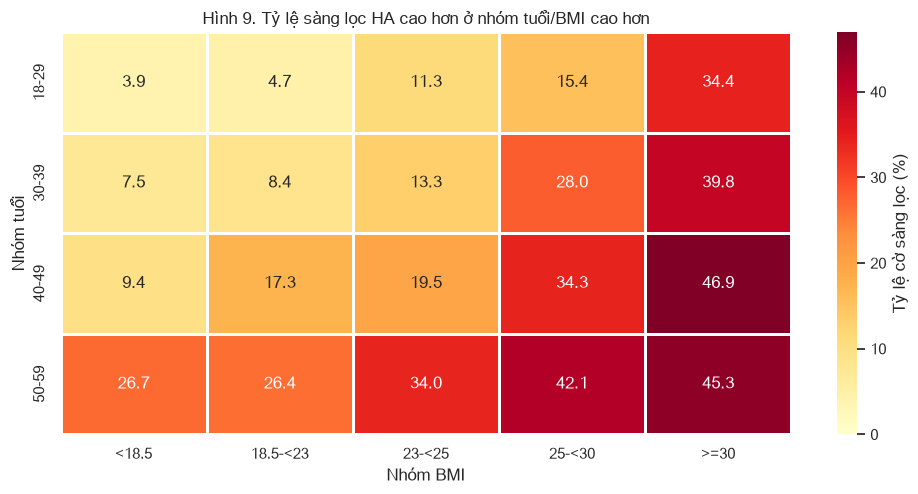

bmi_group,<18.5,18.5-<23,23-<25,25-<30,>=30
age_group,,,,,
18-29,3.9,4.7,11.3,15.4,34.4
30-39,7.5,8.4,13.3,28.0,39.8
40-49,9.4,17.3,19.5,34.3,46.9
50-59,26.7,26.4,34.0,42.1,45.3


In [21]:
# Hình 9. Heatmap tỷ lệ cờ sàng lọc HA theo tuổi × nhóm BMI.
heat = df.pivot_table(index='age_group', columns='bmi_group', values='bp_screen', aggfunc='mean', observed=False)
heat = heat.reindex(index=['18-29','30-39','40-49','50-59'], columns=order_bmi) * 100
fig, ax = plt.subplots(figsize=(10, 5.1))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.8, linecolor='white',
            cbar_kws={'label':'Tỷ lệ cờ sàng lọc (%)'}, vmin=0, vmax=max(40, np.nanmax(heat.to_numpy())), ax=ax)
ax.set(title='Hình 9. Tỷ lệ sàng lọc HA cao hơn ở nhóm tuổi/BMI cao hơn', xlabel='Nhóm BMI', ylabel='Nhóm tuổi')
fig.tight_layout()
fig.savefig(FIG_DIR/'09_screening_heatmap_age_bmi.png', dpi=180, bbox_inches='tight')
plt.show()
heat.round(1)

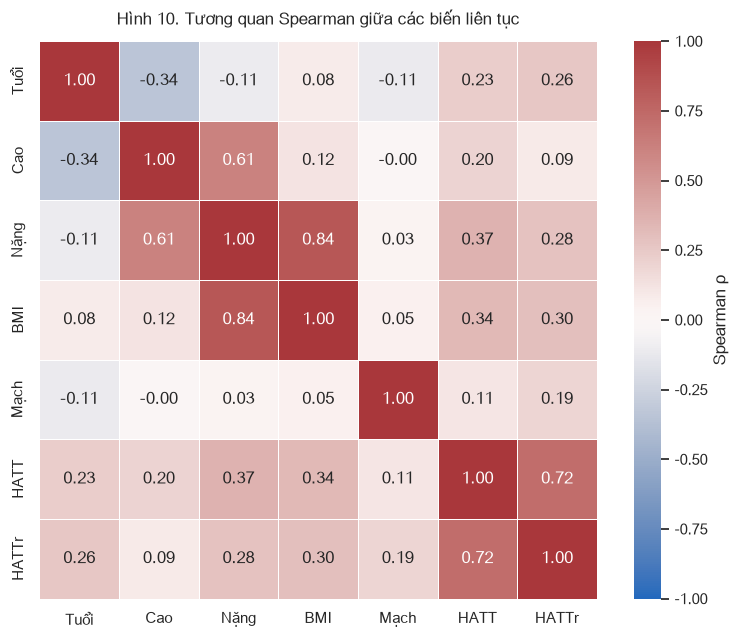

In [22]:
# Hình 10. Ma trận tương quan các biến số liên tục.
corr_matrix = df[['age','height_cm','weight_kg','bmi','pulse','sbp','dbp']].corr(method='spearman')
label_map = {'age':'Tuổi','height_cm':'Cao','weight_kg':'Nặng','bmi':'BMI','pulse':'Mạch','sbp':'HATT','dbp':'HATTr'}
corr_display = corr_matrix.rename(index=label_map, columns=label_map)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_display, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={'label':'Spearman ρ'}, ax=ax)
ax.set_title('Hình 10. Tương quan Spearman giữa các biến liên tục', fontweight='bold', pad=12)
fig.tight_layout()
fig.savefig(FIG_DIR/'10_spearman_correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

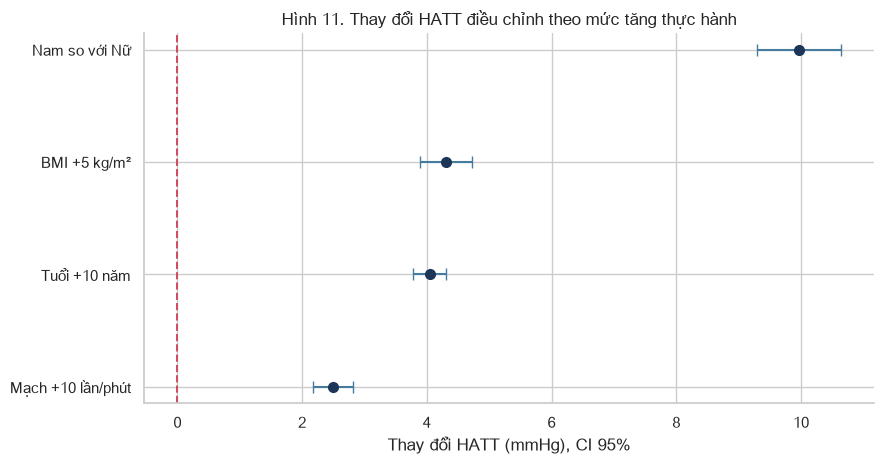

,Nhãn,Hệ số theo mức tăng,CI thấp theo mức tăng,CI cao theo mức tăng,p-value
3,Mạch +10 lần/phút,2.498,2.182,2.813,0.0
1,Tuổi +10 năm,4.047,3.785,4.308,0.0
0,BMI +5 kg/m²,4.304,3.888,4.720,0.0
2,Nam so với Nữ,9.967,9.295,10.638,0.0


In [23]:
# Hình 11. Forest plot ở mức tăng có ý nghĩa thực hành để so sánh công bằng giữa các biến.
# BMI: +5 kg/m²; tuổi: +10 năm; mạch: +10 lần/phút; giới: Nam so với Nữ.
scales = np.array([5, 10, 1, 10])
forest = regression.iloc[1:].copy().reset_index(drop=True)
forest['Hệ số theo mức tăng'] = forest['Hệ số β'] * scales
forest['CI thấp theo mức tăng'] = forest['CI 95% thấp'] * scales
forest['CI cao theo mức tăng'] = forest['CI 95% cao'] * scales
forest['Nhãn'] = ['BMI +5 kg/m²', 'Tuổi +10 năm', 'Nam so với Nữ', 'Mạch +10 lần/phút']
forest = forest.sort_values('Hệ số theo mức tăng')
fig, ax = plt.subplots(figsize=(9, 4.8))
ypos = np.arange(len(forest))
ax.errorbar(forest['Hệ số theo mức tăng'], ypos, xerr=[forest['Hệ số theo mức tăng']-forest['CI thấp theo mức tăng'], forest['CI cao theo mức tăng']-forest['Hệ số theo mức tăng']],
            fmt='o', color='#1D3557', ecolor='#457B9D', capsize=4, markersize=7)
ax.axvline(0, color='#D1495B', ls='--', lw=1.4)
ax.set_yticks(ypos, forest['Nhãn'])
ax.set(title='Hình 11. Thay đổi HATT điều chỉnh theo mức tăng thực hành', xlabel='Thay đổi HATT (mmHg), CI 95%')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'11_regression_forest_plot.png', dpi=180, bbox_inches='tight')
plt.show()
forest[['Nhãn','Hệ số theo mức tăng','CI thấp theo mức tăng','CI cao theo mức tăng','p-value']].round(3)

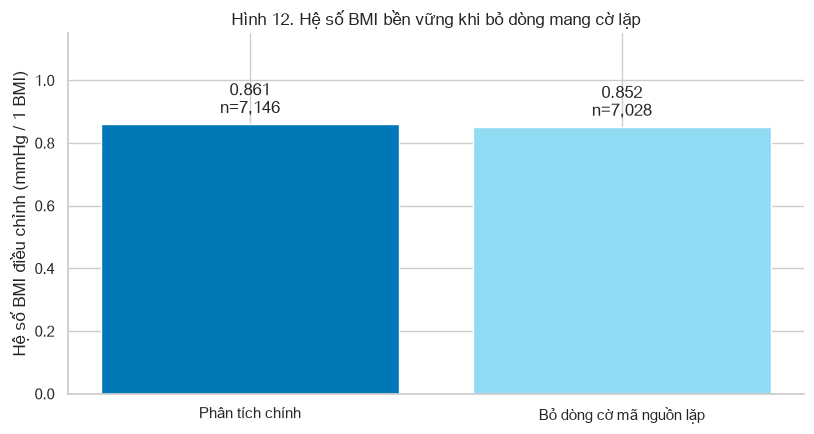

In [24]:
# Hình 12. Kiểm tra độ bền trước quyết định xử lý mã nguồn lặp.
fig, ax = plt.subplots(figsize=(8.3, 4.5))
bars = ax.bar(sensitivity['Mẫu'], sensitivity['Hệ số BMI (mmHg / 1 BMI)'], color=['#0077B6','#90DBF4'])
ax.set(title='Hình 12. Hệ số BMI bền vững khi bỏ dòng mang cờ lặp', ylabel='Hệ số BMI điều chỉnh (mmHg / 1 BMI)')
ax.set_ylim(0, 1.15)
for bar, value, n_value in zip(bars, sensitivity['Hệ số BMI (mmHg / 1 BMI)'], sensitivity['n']):
    ax.text(bar.get_x()+bar.get_width()/2, value+.035, f'{value:.3f}\nn={n_value:,}', ha='center', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'12_sensitivity_repeat_flag.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Đối chiếu với nghiên cứu đã công bố

- Nghiên cứu cắt ngang ở Việt Nam của **Nguyen Minh & Nguyen Vo (2020)** khảo sát 1.636 người trưởng thành và xem xét mối liên quan giữa chỉ số nhân trắc với huyết áp cao. Kết quả hiện tại cũng cho thấy BMI và chỉ số huyết áp/cờ sàng lọc có liên quan trong một mẫu Việt Nam, nhưng không có vòng eo nên **không thể** so sánh hay kết luận chỉ số nào dự báo tốt hơn.
- Nghiên cứu quần thể Việt Nam của **Wang và cộng sự (2018)** nhấn mạnh vòng eo có thể cung cấp thông tin bổ sung cho đánh giá nguy cơ tim mạch. Đây là giới hạn cấu trúc của dữ liệu hiện tại và là biến nên bổ sung ở đợt thu thập sau.
- Các nghiên cứu Việt Nam cũng cho thấy tuổi và giới là các yếu tố liên quan quan trọng với huyết áp. Việc điều chỉnh tuổi, giới và mạch trong mô hình hiện tại giúp hạn chế, nhưng không loại bỏ hoàn toàn, nhiễu còn sót do thiếu thông tin về thuốc, hút thuốc, rượu, muối, vận động và bệnh nền.

**Tài liệu để trích dẫn trong báo cáo:**

1. Nguyen Minh Q, Nguyen Vo M. *Anthropometric Indexes for Predicting High Blood Pressure in Vietnamese Adults: A Cross-Sectional Study.* Integr Blood Press Control. 2020;13:181–186. doi:10.2147/IBPC.S281996.
2. Wang J, et al. *The importance of waist circumference and body mass index in cross-sectional relationships with risk of cardiovascular disease in Vietnam.* PLoS One. 2018. PMID:29813112.
3. Nguyen Duc N, et al. *Impact of body mass index and waist circumference on blood pressure: A cross-sectional survey in a population living in the Vietnam northern mountainous.* Diabetes Metab Syndr. 2019;13(2):1399–1404. doi:10.1016/j.dsx.2019.02.015.


### Kết luận báo cáo

1. Bộ dữ liệu phân tích gồm **7.146** lượt khám, không có dữ liệu thiếu hay mã nghiên cứu trùng trong tập đã phát hành.
2. BMI và HATT được mô tả bằng phân phối, phân nhóm và biểu đồ liên tục; mọi điểm cực trị IQR được ghi nhận thay vì tự động loại bỏ.
3. Các kiểm định và mô hình hồi quy ở trên cung cấp bằng chứng về **mối liên quan thống kê trong mẫu khám**. Khi viết báo cáo, diễn giải hệ số BMI là mức thay đổi HATT *liên quan với* một đơn vị BMI, sau khi xét các biến trong mô hình.
4. Không diễn giải cờ sàng lọc HA ≥140/90 như chẩn đoán và không nói BMI “gây” tăng huyết áp. Mẫu là lượt khám cộng đồng đã tuyển chọn, không phải mẫu đại diện quốc gia hay đoàn hệ theo dõi dọc.

**Tệp tạo ra:** bốn hình PNG trong `outputs/M3_BMI_HuyetAp_Final_Project/figures/`; kết quả bảng được lưu trong output của notebook để dùng trực tiếp cho báo cáo và slide.
